# Sequence Analysis Quiz (Compact)

A shorter version of the same quiz on the same two NCBI sequences.

In [1]:
import matplotlib.pyplot as plt
from Bio import SeqIO
from collections import Counter
from Bio.SeqUtils import gc_fraction
from Bio.SeqUtils import MeltingTemp as mt
from Bio.SeqUtils import molecular_weight as mw
from Bio.Align import PairwiseAligner
from itertools import islice
from Levenshtein import distance

In [2]:
seq_a = SeqIO.read('NC_035298.fasta', 'fasta').seq
seq_b = SeqIO.read('MK312630.fasta', 'fasta').seq
print(f'Sequence A: {seq_a}')
print(f'Sequence B: {seq_b}')

Sequence A: ...
Sequence B: ATGAGTATTACCACTATGAAAGGAGTTACATCAGAGAGTCCTGCCGAAGCGCTTTCCCGCTTCCAAACTACTGGATTGACGTTGAACAACCCCAAGGACCTTTACTGGATGACAGAATTTTTGAAGGAAGAATTTTACGACAAGGGAAACTATTATTATCCCATCAAAACGGTATGTGATGGCGAACTCATCGAAACCGAGCTCTTCTGTCCCTTCGAACCAAAGCTCAGTCCACATTACATTCAATTATACAACTCTCGTGATGAGCGATCCAACTTGTACGCCGTTCCGCCCAAGAAAACAGACATGAAAAAGTACAATCGTATAAATTGTGAGAAAATGGGTTCTTTGATGGCCCCTAATTCCAATTATGACGACACAGAAATGGTTTCTCTCTTCTACTCCATGATGTACTACCTCAATGATCAGACCGCTCATCTTAAGCTCCCTGAAGAAGATATTCAACCTGAGCTTGTTGATGAACTCAACGACCATGTCTTACAGTATCTAAGTGTGTTCCTTAGCATCTTTAAACCGCGTGAACCTCAAGATTTGGAGCGAATCTGGAATTTTTTGGACTTTTACCAGCCATATTTCAAGAAAGTTGATGGCAAGATTATCTTGCACGAGAAATATCAGGGGCGTACTCCACCACAAATCGGTTTGATCAAGAAAATAACAGGTTATGTATTAGAGAGGTTTGCTCCGAAAAAGAATATCACTCAAGTCATCTACGAGGTCATCAGATATATCAAGGGAATCAAGCAAGAAATTAAGATTCGAGGTGATAAGAGCTTCACTCTGTCTCTCAAAGAGTATGATGAGTTCCGTGACCAAGTTACGTCCAGCCCAATGGCTCATTCGATTACAGATCTTACTTATGACGACTTCTCTTACAAGGCATACATGAACCCACTCTTCATCAAGCTGGAAGATCTAACCTCTGAGATCATCACGTACTTCAACGACGTT

In [3]:
print(f'Sequence A Length: {len(seq_a)}')
print(f'Sequence B Length: {len(seq_b)}')

Sequence A Length: 174848
Sequence B Length: 12381


In [4]:
a_gct = seq_a.find('GCT')
b_gct = seq_b.find('GCT')
print(f'Sequence A: {a_gct}')
print(f'Sequence B: {b_gct}')

Sequence A: 18
Sequence B: 50


In [5]:
first = seq_a[:13]
last = seq_b[-2:]
seq_c = (first + last)[::-1]
print(f'Sequence C: {seq_c}')

Sequence C: AAAGTTTGAGAGGTA


Counter({'T': 61770, 'A': 61016, 'G': 26348, 'C': 25714})


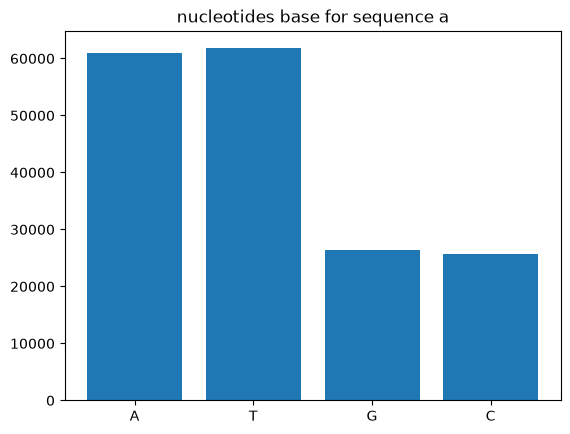

Counter({'A': 4228, 'T': 3566, 'C': 2331, 'G': 2256})


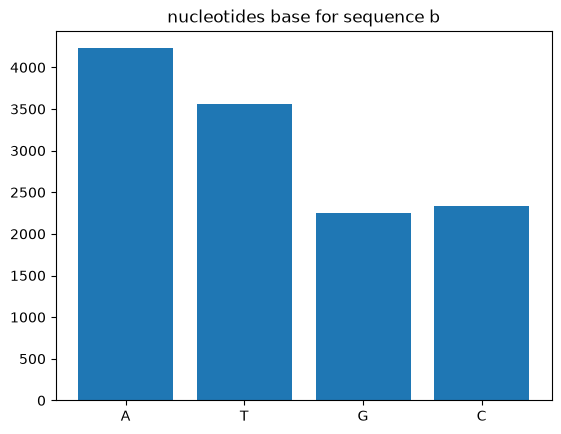

Counter({'A': 6, 'G': 5, 'T': 4})


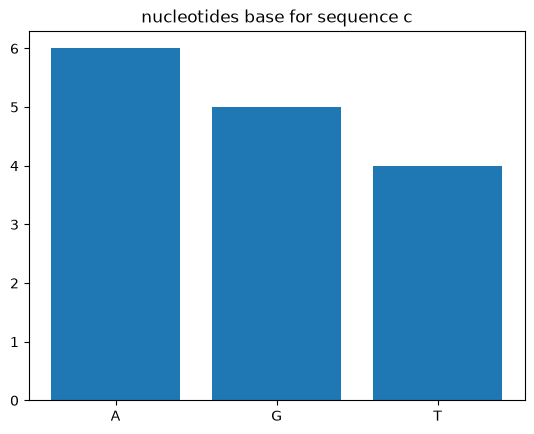

In [6]:
count_a = Counter(seq_a)
count_b = Counter(seq_b)
count_c = Counter(seq_c)

print(count_a)
plt.bar(count_a.keys(), count_a.values())
plt.title('nucleotides base for sequence a')
plt.show()

print(count_b)
plt.bar(count_b.keys(), count_b.values())
plt.title('nucleotides base for sequence b')
plt.show()

print(count_c)
plt.bar(count_c.keys(), count_c.values())
plt.title('nucleotides base for sequence c')
plt.show()

In [7]:
a_gc = gc_fraction(seq_a) * 100
a_at = 100 - a_gc
print(f'Sequence A: GC ({a_gc:.2f}%), AT ({a_at:.2f}%)')

b_gc = gc_fraction(seq_b) * 100
b_at = 100 - b_gc
print(f'Sequence B: GC ({b_gc:.2f}%), AT ({b_at:.2f}%)')

c_gc = gc_fraction(seq_c) * 100
c_at = 100 - c_gc
print(f'Sequence C: GC ({c_gc:.2f}%), AT ({c_at:.2f}%)')

Sequence A: GC (29.78%), AT (70.22%)
Sequence B: GC (37.05%), AT (62.95%)
Sequence C: GC (33.33%), AT (66.67%)


In [8]:
print(f'Sequence A Melting Temp: {mt.Tm_Wallace(seq_a)}')
print(f'Sequence B Melting Temp: {mt.Tm_Wallace(seq_b)}')
print(f'Sequence C Melting Temp: {mt.Tm_Wallace(seq_c)}')

Sequence A Melting Temp: 453820.0
Sequence B Melting Temp: 33936.0
Sequence C Melting Temp: 40.0


In [9]:
# 2d
print(f'Sequence A Molecular Weight: {mw(seq_a)}')
print(f'Sequence B Molecular Weight: {mw(seq_b)}')
print(f'Sequence C Molecular Weight: {mw(seq_c)}')

Sequence A Molecular Weight: 54010577.6417
Sequence B Molecular Weight: 3825779.3347
Sequence C Molecular Weight: 4760.0566


In [10]:
mrna_a = seq_a.transcribe()
mrna_b = seq_b.transcribe()
mrna_c = seq_c.transcribe()
print(f'mRNA A: {mrna_a}')
print(f'mRNA B: {mrna_b}')
print(f'mRNA C: {mrna_c}')

mRNA A: ...
mRNA B: AUGAGUAUUACCACUAUGAAAGGAGUUACAUCAGAGAGUCCUGCCGAAGCGCUUUCCCGCUUCCAAACUACUGGAUUGACGUUGAACAACCCCAAGGACCUUUACUGGAUGACAGAAUUUUUGAAGGAAGAAUUUUACGACAAGGGAAACUAUUAUUAUCCCAUCAAAACGGUAUGUGAUGGCGAACUCAUCGAAACCGAGCUCUUCUGUCCCUUCGAACCAAAGCUCAGUCCACAUUACAUUCAAUUAUACAACUCUCGUGAUGAGCGAUCCAACUUGUACGCCGUUCCGCCCAAGAAAACAGACAUGAAAAAGUACAAUCGUAUAAAUUGUGAGAAAAUGGGUUCUUUGAUGGCCCCUAAUUCCAAUUAUGACGACACAGAAAUGGUUUCUCUCUUCUACUCCAUGAUGUACUACCUCAAUGAUCAGACCGCUCAUCUUAAGCUCCCUGAAGAAGAUAUUCAACCUGAGCUUGUUGAUGAACUCAACGACCAUGUCUUACAGUAUCUAAGUGUGUUCCUUAGCAUCUUUAAACCGCGUGAACCUCAAGAUUUGGAGCGAAUCUGGAAUUUUUUGGACUUUUACCAGCCAUAUUUCAAGAAAGUUGAUGGCAAGAUUAUCUUGCACGAGAAAUAUCAGGGGCGUACUCCACCACAAAUCGGUUUGAUCAAGAAAAUAACAGGUUAUGUAUUAGAGAGGUUUGCUCCGAAAAAGAAUAUCACUCAAGUCAUCUACGAGGUCAUCAGAUAUAUCAAGGGAAUCAAGCAAGAAAUUAAGAUUCGAGGUGAUAAGAGCUUCACUCUGUCUCUCAAAGAGUAUGAUGAGUUCCGUGACCAAGUUACGUCCAGCCCAAUGGCUCAUUCGAUUACAGAUCUUACUUAUGACGACUUCUCUUACAAGGCAUACAUGAACCCACUCUUCAUCAAGCUGGAAGAUCUAACCUCUGAGAUCAUCACGUACUUCAACGACGUUUGCACAUG

In [11]:
print(f'Amono Acid A: {mrna_a.translate()}')
print(f'Amono Acid B: {mrna_b.translate()}')
print(f'Amono Acid C: {mrna_c.translate()}')

Amono Acid A: MESLILAQDERWRYALHMQVERKL*L*WRTGE*HVRIYL*EGNNNWKRLLTSHML*SEIIFCLEMSLRLIS*LVR*WLTKATISSWFERTISHTGTETRSRLLRKAAVGNFPQWAKA*RSNTA*GMNACGL*TSFIGEEF*RYPKNKHRLTPCQQPR*YGGCKRYPELLGVKSLQVVS*VCC*ILELNSKQAVETIILEYGRGKGNSQCSGEMRRYWEEHQKRKRFAGPLLTLRDES*GSEWD*IPQ*S*P*TMDTRCCAYRSVQYRS*RVKYPAWEVCSQE*NSKELTGARTSGGACGLIRCNTKNLTRI*HVVDFYESRKCLREHEHRWCMAVVSSCREMLG*VPQRAQPLFLVAII*LGTLKRLPVTNRRKVRMTSSQHAPYILGYTRATMGMTKSC*TVKSSQSLNIFSVRIVG*NSPT*RWNR**SPVSYTAVNPFPGLVHTARHTTGAGHARSYCLALSVPKVGLVTGVKS*QGSRTGRCGWITSLLGIYLFISDRYI*RAISSVG*SAPLIRVRSQVQILDSPDLGGYSSVGRALLLQGRCQRFESAYLQRYI*LF*IYIYCAYVYVCVN*LLLVSSKLRLTMDTLAFRSDEGRDYQRNISVSWK*AMTRKFPNEETLYTVY*IHK*IRANLVN*NILVTKGKESKSDFLSSGERKGNSLNHFNAF*WGRGTLVT*LSKIS*NSWNIVP**GESPVGENV*KIINVSQVAWDT*NPV*ISEDHLVRLNIPK*PIVN*YREGKVKRTPGGE*NRT*NRKLTSSRRTTYRLTMCMLKNEPATYK*WQVKIENIGAIVKASLNRALVTVYRPEPE*SNHGQGEA*VVLSGGPNRLMLKNQRTSCG*G*NANRIRS*LVLPEMRFGAAVDAIA*G*STVSVRAAKAVPNQGKL*ILSE*STSETVGDKLHCQKGNSPDHHLRPLNDY*VAKEVRMLIQPGGLLRSSNPLKSA**LTGLVILRRK*MGLSNLPKMWDVLHR*GS

C:\Users\jorda\Code\ml-notebooks\courses\computational-biology\.venv\Lib\site-packages\Bio\Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


In [12]:
# xx scoring: match = 1, mismatch = 0, no gap penalty
aligner = PairwiseAligner(mode='local', match_score=1, mismatch_score=0, open_gap_score=0, extend_gap_score=0)

alignment_a = aligner.align(seq_a, 'TAACGCGTTAAGTATCCCG')
a = alignment_a[0]
print(a)
print(f'Score: {a.score}')

target            1 TGGAGAGTTTGATCCTGGCTCAGGATGAACGCTGGCGGTATGCCTTACACATGCAAGTCG
                  0 |--|-|-------|--|-|---|--|------|------|------|-----|----|--
query             0 T--A-A-------C--G-C---G--T------T------A------A-----G----T--

target           61 AACGAAAGCTTTAGCTTTAGTGGCGAACG 90
                 60 |--------|----|--------|---|| 89
query            13 A--------T----C--------C---CG 19

Score: 19.0


In [13]:
alignment_b = aligner.align(seq_b, 'CTCTTGATACCAATAAAAT')
print(f'Best local alignment score: {alignment_b.score} (showing the first 3 optimal alignments)')
for a in islice(alignment_b, 3):
    print(a)

Best local alignment score: 19.0 (showing the first 3 optimal alignments)
target           10 CCACTATGAAAGGAGTTACATCAGAGAGTCCTGCCGAAGCGCTTTCCCGCTTCCAAACTA
                  0 |---|-------------|-|-------|---|---|-----|-----------|--|--
query             0 C---T-------------C-T-------T---G---A-----T-----------A--C--

target           70 CTGGATTGACGTTGAACAACCCCAAGGACCT 101
                 60 |---|---|--|--||-||-----------|  91
query            10 C---A---A--T--AA-AA-----------T  19

target           11 CACTATGAAAGGAGTTACATCAGAGAGTCCTGCCGAAGCGCTTTCCCGCTTCCAAACTAC
                  0 |--|-------------|-|-------|---|---|-----|-----------|--|--|
query             0 C--T-------------C-T-------T---G---A-----T-----------A--C--C

target           71 TGGATTGACGTTGAACAACCCCAAGGACCT 101
                 60 ---|---|--|--||-||-----------|  90
query            11 ---A---A--T--AA-AA-----------T  19

target           13 CTATGAAAGGAGTTACATCAGAGAGTCCTGCCGAAGCGCTTTCCCGCTTCCAAACTACTG
                  0 ||

In [14]:
print(f'Sequence A & B Levenshtein Distance: {distance(seq_a, seq_b)}')

Sequence A & B Levenshtein Distance: 162467


In [15]:
def humming(a, b):
    mismatch = []
    for x, y in zip(a, b):
        if x != y:
            mismatch.append((x, y))
    return len(mismatch)

humming(seq_a, seq_b)

9037